Analyze time-series data from platereader experiments.

## Setup

In [ ]:
try:
    import cdk
    print("CDK already installed, skipping installation and restart.")
except ImportError:
    !pip install nucleus-cdk==0.6.2 -q > /dev/null 2>&1
    print("\nInstallation complete. Restarting runtime to refresh dependencies...")
    import os
    os._exit(0)

CDK already installed, skipping installation and restart.


In [ ]:

import pandas as pd
pd.set_option('display.max_columns', None)
import seaborn as sns
import matplotlib.pyplot as plt

# Import the cdk platereader module
from cdk.instruments import platereader as pr

from cdk import logging
log = logging.setup_logging(logging.ERROR)

## Load Data

In [ ]:
%%writefile drive_utils.py
import os
import re

import gdown


def get_drive_file_id(url):
    """Extract the file ID from a Google Drive share URL."""
    match = re.search(r'/d/([a-zA-Z0-9_-]+)', url)
    if match:
        return match.group(1)
    return None


def download_from_drive(files_info, destination_dir):
    """
    Download files from Google Drive.

    Args:
        files_info (list): List of dicts with 'url' and 'filename'.
        destination_dir (str): Local path to save files.
    Returns:
        dict: Mapping of filenames to local paths.
    """
    os.makedirs(destination_dir, exist_ok=True)

    paths = {}
    for item in files_info:
        url = item['url']
        filename = item['filename']
        dest = os.path.join(destination_dir, filename)
        file_id = get_drive_file_id(url)

        if file_id:
            gdown.download(id=file_id, output=dest, quiet=True)
        else:
            gdown.download(url, output=dest, quiet=True)

        paths[filename] = dest
    return paths

Writing drive_utils.py


In [ ]:
# Set use_drive = True to download data_file and platemap_file from Google Drive instead of
# using local files. Each Drive file must have its permissions set to "Anyone with a link" can "view".
use_drive = True

if use_drive:
    from drive_utils import download_from_drive

    files_to_download = [
        {
            "url": "https://drive.google.com/file/d/1BZ9z8nwe9Fla6StBErmYg-xxrzUP8LhS/view?usp=share_link",  # Replace with your data file link.
            "filename": "raw_data.txt",
        },
        {
            "url": "https://drive.google.com/file/d/1w3VMTSl3TASXHwFqyztAMoGXTRVQ3tzy/view?usp=share_link",  # Replace with your platemap file link.
            "filename": "platemap.csv",
        },
    ]
    downloaded_paths = download_from_drive(files_to_download, destination_dir="data")
    data_file = downloaded_paths["raw_data.txt"]
    platemap_file = downloaded_paths["platemap.csv"]
else:
    data_file = "sample-data/20251111-122213-cytation5-pure-timecourse-gfp-MFG-98-tRNA-QC.txt"
    platemap_file = "sample-data/platemap.csv"

print(f"Data file: {data_file}\nPlatemap file: {platemap_file}")

Data file: data/raw_data.txt
Platemap file: data/platemap.csv


In [ ]:
# Load data
result = pr.load_platereader_data(
    data_file=data_file,
    platemap_file=platemap_file,
    platereader="biotek" # options: "biotek"
)

The output is a list of `PlateReaderResult` objects; if you did more than one read on the plate reader, the results will be in separate objects.

In [ ]:
print(result)

PlateReaderResult with the following 6 blocks:
0: (6059, 40) kinetic read with reads: GFP-G65:485/20,528/20 (Fluorescence) (Plate 'Plate 1')
1: (6059, 40) kinetic read with reads: GFP-G35:485/20,528/20 (Fluorescence) (Plate 'Plate 1')
2: (996, 38) endpoint read with reads: Max V [GFP-G65:485/20,528/20] (Fluorescence), R-Squared [GFP-G65:485/20,528/20] (Fluorescence), t at Max V [GFP-G65:485/20,528/20] (Fluorescence), Lagtime [GFP-G65:485/20,528/20] (Fluorescence), Max V [GFP-G35:485/20,528/20] (Fluorescence), R-Squared [GFP-G35:485/20,528/20] (Fluorescence), t at Max V [GFP-G35:485/20,528/20] (Fluorescence), Lagtime [GFP-G35:485/20,528/20] (Fluorescence), Count (None), Mean (None), Std Dev (None), CV (%) (None) (Plate 'Plate 1')
3: (6059, 40) kinetic read with reads: GFP-G65:485/20,528/20 (Fluorescence) (Plate 'Plate 1')
4: (6059, 40) kinetic read with reads: GFP-G35:485/20,528/20 (Fluorescence) (Plate 'Plate 1')
5: (996, 38) endpoint read with reads: Max V [GFP-G65:485/20,528/20] (Flu

Here there were two reads with different gains but the same excitation/emission spectrum, on one plate. If we want just the `GFP-Gext` read, this corresponds to block index 1, so we can extract that block by indexing:

In [ ]:
desired_index = 1
data = result[desired_index]

You can see the underlying data with `data.view()` (which returns a Pandas DataFrame):

In [ ]:
data.view().head()

,Date,Experiment,Well,Name,Type,Time,Data,Read,Read Name,Reader Type,Reader ID,Plate Type,Plate ID,Start Time,Read Modality,Gain,Excitation Wavelength (nm),Excitation Bandwidth (nm),Excitation Optics,Emission Wavelength (nm),Emission Bandwidth (nm),Emission Optics,Read Geometry,Read Height (mm),Rxn Volume (uL),EsaR Vol (uL),DNA Template (nM),[AHSL] (uM),[Fluorescein] (uM)
0,2026-09-24,EsaO-mNG / [EsaO]2-mNG DNA template titration ...,B2,mNG,Sample,0 days 00:01:17,5,"GFP-G35:485/20,528/20",GFP-G35,Synergy 2,206621,Greiner 384 SV NoBind Automap,Plate 1,2026-09-25 16:07:48,Fluorescence,35,485,20,filter,528,20,filter,Top 510 nm,7 mm,10,0.0,0.0,0,NaN
1,2026-09-24,EsaO-mNG / [EsaO]2-mNG DNA template titration ...,B2,mNG,Sample,0 days 00:06:17,5,"GFP-G35:485/20,528/20",GFP-G35,Synergy 2,206621,Greiner 384 SV NoBind Automap,Plate 1,2026-09-25 16:07:48,Fluorescence,35,485,20,filter,528,20,filter,Top 510 nm,7 mm,10,0.0,0.0,0,NaN
2,2026-09-24,EsaO-mNG / [EsaO]2-mNG DNA template titration ...,B2,mNG,Sample,0 days 00:11:17,30,"GFP-G35:485/20,528/20",GFP-G35,Synergy 2,206621,Greiner 384 SV NoBind Automap,Plate 1,2026-09-25 16:07:48,Fluorescence,35,485,20,filter,528,20,filter,Top 510 nm,7 mm,10,0.0,0.0,0,NaN
3,2026-09-24,EsaO-mNG / [EsaO]2-mNG DNA template titration ...,B2,mNG,Sample,0 days 00:16:17,140,"GFP-G35:485/20,528/20",GFP-G35,Synergy 2,206621,Greiner 384 SV NoBind Automap,Plate 1,2026-09-25 16:07:48,Fluorescence,35,485,20,filter,528,20,filter,Top 510 nm,7 mm,10,0.0,0.0,0,NaN
4,2026-09-24,EsaO-mNG / [EsaO]2-mNG DNA template titration ...,B2,mNG,Sample,0 days 00:21:17,314,"GFP-G35:485/20,528/20",GFP-G35,Synergy 2,206621,Greiner 384 SV NoBind Automap,Plate 1,2026-09-25 16:07:48,Fluorescence,35,485,20,filter,528,20,filter,Top 510 nm,7 mm,10,0.0,0.0,0,NaN


## Plot Raw Curves

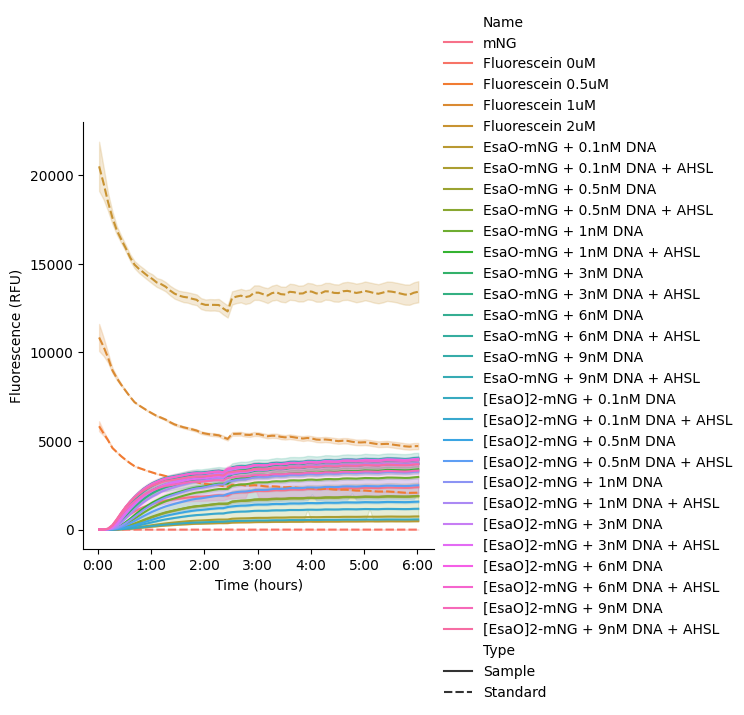

In [ ]:
data.plot(style='Type')

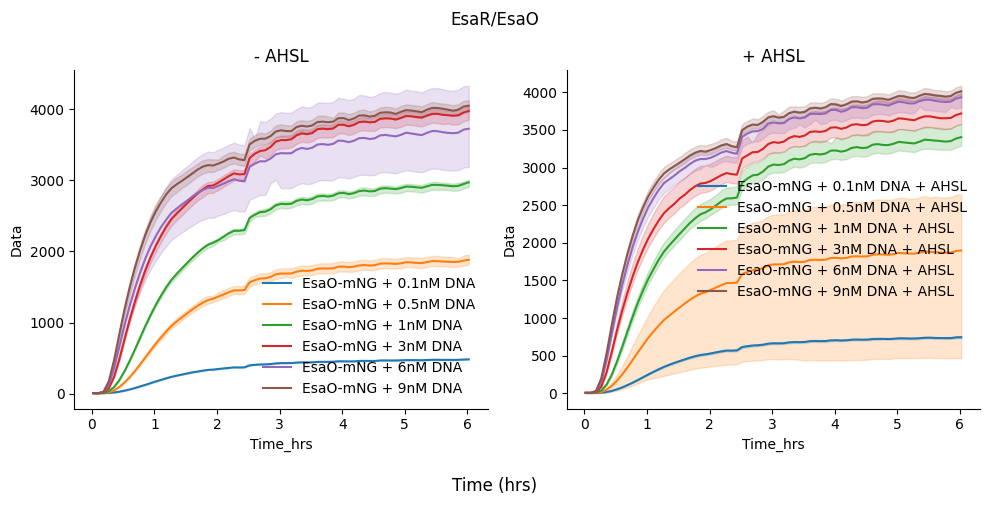

In [ ]:
data_EsaO = data.select(name=["EsaO-mNG + 0.1nM DNA", "EsaO-mNG + 0.5nM DNA",
                              "EsaO-mNG + 1nM DNA", "EsaO-mNG + 3nM DNA", "EsaO-mNG + 6nM DNA", "EsaO-mNG + 9nM DNA"])
data_EsaO_AHSL = data.select(name=["EsaO-mNG + 0.1nM DNA + AHSL", "EsaO-mNG + 0.5nM DNA + AHSL",
                                   "EsaO-mNG + 1nM DNA + AHSL", "EsaO-mNG + 3nM DNA + AHSL", "EsaO-mNG + 6nM DNA + AHSL", "EsaO-mNG + 9nM DNA + AHSL"])

df_1 = data_EsaO.data
df_2 = data_EsaO_AHSL.data


# convert timedelta -> float hours
for df in (df_1, df_2):
    df['Time_hrs'] = df['Time'].dt.total_seconds() / 3600

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10,5), sharex=True)
fig.suptitle('EsaR/EsaO')

sns.lineplot(data=df_1, x='Time_hrs', y='Data', hue='Name', ax=ax1)
sns.lineplot(data=df_2, x='Time_hrs', y='Data', hue='Name', ax=ax2)

ax1.set(title='- AHSL')
ax2.set(title='+ AHSL')
fig.supxlabel('Time (hrs)')

for ax in (ax1, ax2):
    ax.legend(frameon=False)

sns.despine(fig)
fig.tight_layout()


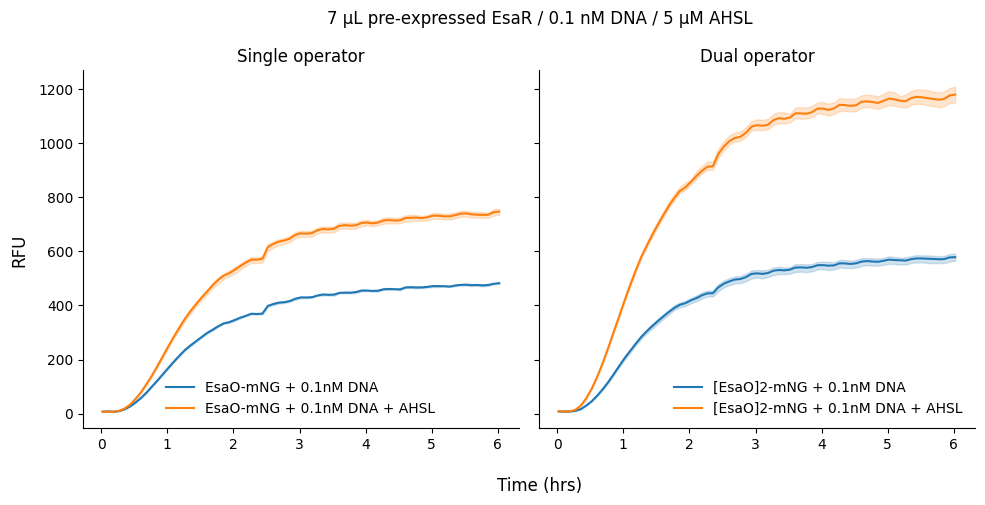

In [ ]:
#| label: cn-20260925-fig1

data_EsaO_01 = data.select(name=["EsaO-mNG + 0.1nM DNA", "EsaO-mNG + 0.1nM DNA + AHSL"])
data_EsaO2_01 = data.select(name=["[EsaO]2-mNG + 0.1nM DNA", "[EsaO]2-mNG + 0.1nM DNA + AHSL"])

df_1 = data_EsaO_01.data
df_2 = data_EsaO2_01.data


# convert timedelta -> float hours
for df in (df_1, df_2):
    df['Time_hrs'] = df['Time'].dt.total_seconds() / 3600

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10,5), sharey=True)
fig.suptitle('7 µL pre-expressed EsaR / 0.1 nM DNA / 5 µM AHSL', x=0.55)

sns.lineplot(data=df_1, x='Time_hrs', y='Data', hue='Name', ax=ax1)
sns.lineplot(data=df_2, x='Time_hrs', y='Data', hue='Name', ax=ax2)

ax1.set(title='Single operator', ylabel='', xlabel='')
ax2.set(title='Dual operator', ylabel='', xlabel='')
fig.supxlabel('Time (hrs)', x=0.55)
fig.supylabel('RFU')



for ax in (ax1, ax2):
    ax.legend(frameon=False)

ax1.legend(loc="lower center", frameon=False)



sns.despine(fig)
fig.tight_layout()


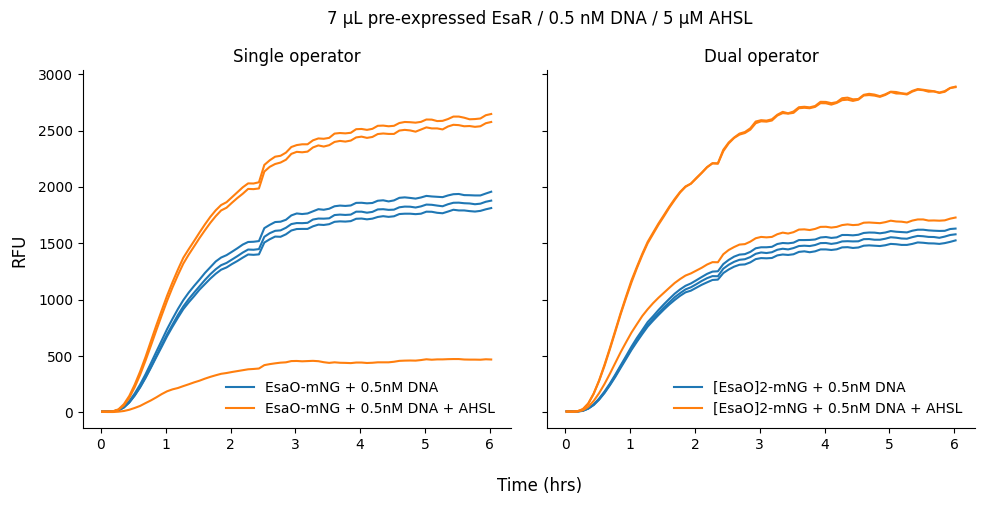

In [ ]:
#| label: cn-20260925-fig2

data_EsaO_05 = data.select(name=["EsaO-mNG + 0.5nM DNA", "EsaO-mNG + 0.5nM DNA + AHSL"])
data_EsaO2_05 = data.select(name=["[EsaO]2-mNG + 0.5nM DNA", "[EsaO]2-mNG + 0.5nM DNA + AHSL"])

df_3 = data_EsaO_05.data
df_4 = data_EsaO2_05.data


# convert timedelta -> float hours
for df in (df_3, df_4):
    df['Time_hrs'] = df['Time'].dt.total_seconds() / 3600

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10,5), sharey=True)
fig.suptitle('7 µL pre-expressed EsaR / 0.5 nM DNA / 5 µM AHSL', x=0.55)

sns.lineplot(data=df_3, x='Time_hrs', y='Data', hue='Name', units='Well', estimator=None, ax=ax1)
sns.lineplot(data=df_4, x='Time_hrs', y='Data', hue='Name', units='Well', estimator=None, ax=ax2)

ax1.set(title='Single operator', ylabel='', xlabel='')
ax2.set(title='Dual operator', ylabel='', xlabel='')
fig.supxlabel('Time (hrs)', x=0.55)
fig.supylabel('RFU')

for ax in (ax1, ax2):
    ax.legend(frameon=False)

    ax1.legend(loc="lower center", frameon=False, bbox_to_anchor=(0.65, 0))
sns.despine(fig)
fig.tight_layout()


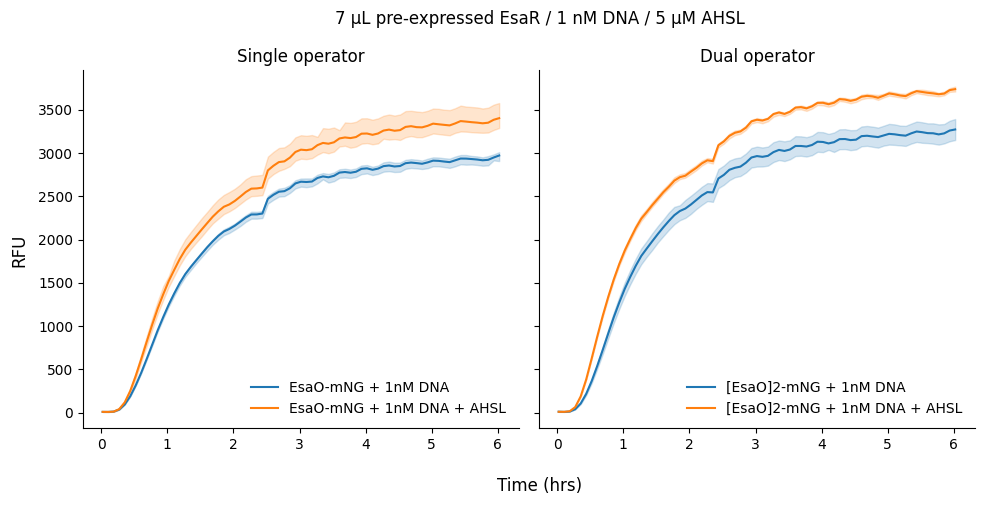

In [ ]:
#| label: cn-20260925-fig3

data_EsaO_1 = data.select(name=["EsaO-mNG + 1nM DNA", "EsaO-mNG + 1nM DNA + AHSL"])
data_EsaO2_1 = data.select(name=["[EsaO]2-mNG + 1nM DNA", "[EsaO]2-mNG + 1nM DNA + AHSL"])

df_5 = data_EsaO_1.data
df_6 = data_EsaO2_1.data


# convert timedelta -> float hours
for df in (df_5, df_6):
    df['Time_hrs'] = df['Time'].dt.total_seconds() / 3600

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10,5), sharey=True)
fig.suptitle('7 µL pre-expressed EsaR / 1 nM DNA / 5 µM AHSL', x=0.55)

sns.lineplot(data=df_5, x='Time_hrs', y='Data', hue='Name', ax=ax1)
sns.lineplot(data=df_6, x='Time_hrs', y='Data', hue='Name', ax=ax2)

ax1.set(title='Single operator', ylabel='', xlabel='')
ax2.set(title='Dual operator', ylabel='', xlabel='')
fig.supxlabel('Time (hrs)', x=0.55)
fig.supylabel('RFU')

for ax in (ax1, ax2):
    ax.legend(frameon=False)

sns.despine(fig)
fig.tight_layout()

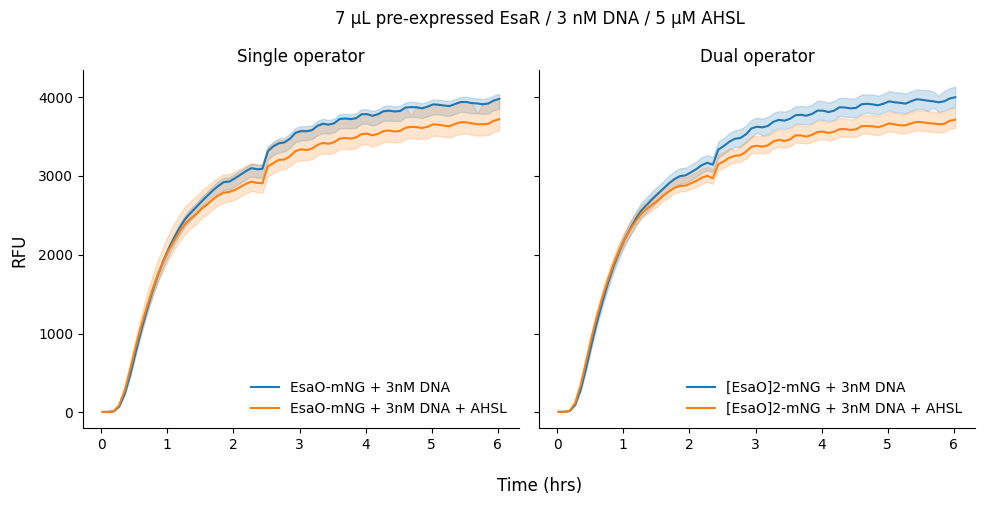

In [ ]:
#| label: cn-20260925-fig4

data_EsaO_3 = data.select(name=["EsaO-mNG + 3nM DNA", "EsaO-mNG + 3nM DNA + AHSL"])
data_EsaO2_3 = data.select(name=["[EsaO]2-mNG + 3nM DNA", "[EsaO]2-mNG + 3nM DNA + AHSL"])

df_7 = data_EsaO_3.data
df_8 = data_EsaO2_3.data


# convert timedelta -> float hours
for df in (df_7, df_8):
    df['Time_hrs'] = df['Time'].dt.total_seconds() / 3600

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10,5), sharey=True)
fig.suptitle('7 µL pre-expressed EsaR / 3 nM DNA / 5 µM AHSL', x=0.55)

sns.lineplot(data=df_7, x='Time_hrs', y='Data', hue='Name', ax=ax1)
sns.lineplot(data=df_8, x='Time_hrs', y='Data', hue='Name', ax=ax2)

ax1.set(title='Single operator', ylabel='', xlabel='')
ax2.set(title='Dual operator', ylabel='', xlabel='')
fig.supxlabel('Time (hrs)', x=0.55)
fig.supylabel('RFU')

for ax in (ax1, ax2):
    ax.legend(frameon=False)

sns.despine(fig)
fig.tight_layout()

In [ ]:

# --- steady-state fold change function (from earlier) ---
def steady_state_fold_change(df, base_name, ahsl_name, n_last=10):
    tail = df.groupby('Name').apply(lambda g: g.nlargest(n_last, 'Time_hrs')['Data'].mean())
    return tail[ahsl_name] / tail[base_name]

# --- compute for all six ---
fc_EsaO_01  = steady_state_fold_change(df_1, "EsaO-mNG + 0.1nM DNA",       "EsaO-mNG + 0.1nM DNA + AHSL")
fc_EsaO2_01 = steady_state_fold_change(df_2, "[EsaO]2-mNG + 0.1nM DNA",    "[EsaO]2-mNG + 0.1nM DNA + AHSL")
fc_EsaO_05  = steady_state_fold_change(df_3, "EsaO-mNG + 0.5nM DNA",       "EsaO-mNG + 0.5nM DNA + AHSL")
fc_EsaO2_05 = steady_state_fold_change(df_4, "[EsaO]2-mNG + 0.5nM DNA",    "[EsaO]2-mNG + 0.5nM DNA + AHSL")
fc_EsaO_1   = steady_state_fold_change(df_5, "EsaO-mNG + 1nM DNA",         "EsaO-mNG + 1nM DNA + AHSL")
fc_EsaO2_1  = steady_state_fold_change(df_6, "[EsaO]2-mNG + 1nM DNA",      "[EsaO]2-mNG + 1nM DNA + AHSL")
fc_EsaO_3   = steady_state_fold_change(df_7, "EsaO-mNG + 3nM DNA",         "EsaO-mNG + 3nM DNA + AHSL")
fc_EsaO2_3  = steady_state_fold_change(df_8, "[EsaO]2-mNG + 3nM DNA",      "[EsaO]2-mNG + 3nM DNA + AHSL")


# --- tidy into one summary table ---
fold_summary = pd.DataFrame({
    'DNA_conc_nM': [0.1, 0.1, 0.5, 0.5, 1, 1, 3, 3],
    'Construct':   ['EsaO', '[EsaO]2', 'EsaO', '[EsaO]2', 'EsaO', '[EsaO]2', 'EsaO', '[EsaO]2'],
    'Fold_change': [fc_EsaO_01, fc_EsaO2_01, fc_EsaO_05, fc_EsaO2_05, fc_EsaO_1, fc_EsaO2_1, fc_EsaO_3, fc_EsaO2_3]
})
print(fold_summary)

   DNA_conc_nM Construct  Fold_change
0         0.10      EsaO         1.55
1         0.10   [EsaO]2         2.05
2         0.50      EsaO         1.05
3         0.50   [EsaO]2         1.61
4         1.00      EsaO         1.15
5         1.00   [EsaO]2         1.14
6         3.00      EsaO         0.94
7         3.00   [EsaO]2         0.92


/tmp/ipykernel_1098/6956029.py:3: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  tail = df.groupby('Name').apply(lambda g: g.nlargest(n_last, 'Time_hrs')['Data'].mean())
/tmp/ipykernel_1098/6956029.py:3: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  tail = df.groupby('Name').apply(lambda g: g.nlargest(n_last, 'Time_hrs')['Data'].mean())
/tmp/ipykernel_1098/6956029.py:3: DeprecationWarning: DataFrameGroupBy.a

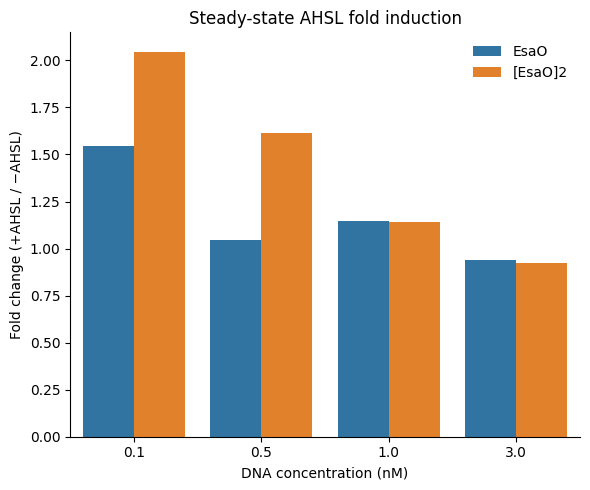

In [ ]:
#| label: cn-20260925-fig5

fig, ax = plt.subplots(figsize=(6,5))

sns.barplot(data=fold_summary, x='DNA_conc_nM', y='Fold_change', hue='Construct',
            ax=ax, palette=['tab:blue', 'tab:orange'])

ax.set(xlabel='DNA concentration (nM)', ylabel='Fold change (+AHSL / −AHSL)')
ax.set_title('Steady-state AHSL fold induction')
ax.legend(frameon=False, title='')

sns.despine(fig)
fig.tight_layout()
plt.show()

We can see that the standard (here, HPTS) is stable and can be safely used for normalization.

## Normalize Data
Now, use `data.normalize('<standard name>')` to normalize your data. This will calculate the average over a time window at the end of the experiment (by default, 1 hour), then divide all data by the mean of that window-average across all wells with the same `Name` (defined by your platemap).

In [ ]:
# To check the exact name of your standard
platemap = data.platemap
standards = platemap[platemap['Type']=='Standard']
standards['Name'].unique()

array(['Fluorescein 0uM', 'Fluorescein 0.5uM', 'Fluorescein 1uM',
       'Fluorescein 2uM'], dtype=object)

In [ ]:
data = data.normalize('Fluorescein 0.5uM')

Now replot your curves to see them normalized:

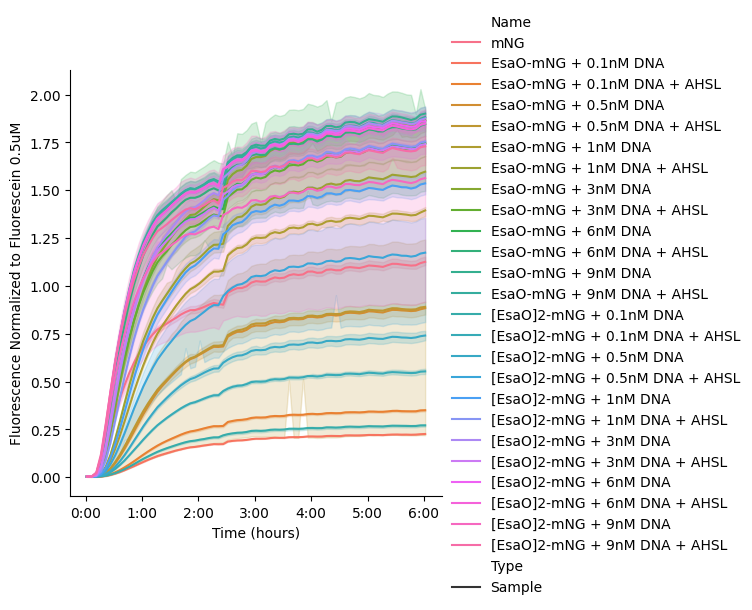

In [ ]:
g = data.plot(style='Type', exclude_types=['Standard'])
# g.savefig('after-normalization.png',dpi=300)

### Replot Normalized Data (Excluding > 1 nM DNA)

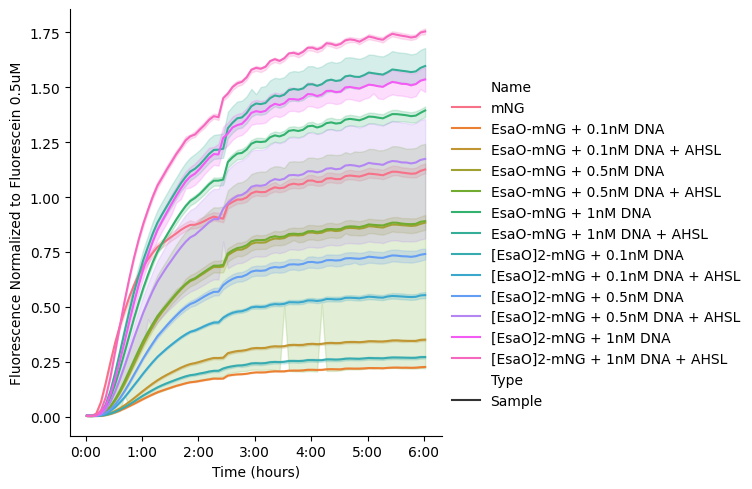

In [ ]:
# Identify names that have <= 1nM DNA (or specifically exclude 3nM, 6nM, and 9nM conditions)
all_names = data.view()['Name'].unique()
filtered_names = [name for name in all_names if not any(x in name for x in ['3nM DNA', '6nM DNA', '9nM DNA'])]

# Select only the filtered conditions
data_filtered = data.select(name=filtered_names)

# Replot the normalized curves
g_filtered = data_filtered.plot(style='Type', exclude_types=['Standard'])


### Export Normalized Data for Comparison

In [ ]:
# Save the filtered, normalized view to a CSV file
data_filtered.view().to_csv('normalized_data_under_1nM.csv', index=False)
print('Data successfully exported to normalized_data_under_1nM.csv')

Data successfully exported to normalized_data_under_1nM.csv


In [ ]:
from google.colab import files
files.download('normalized_data_under_1nM.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Trigger download of the cleaned file
from google.colab import files
files.download('normalized_samples_only.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

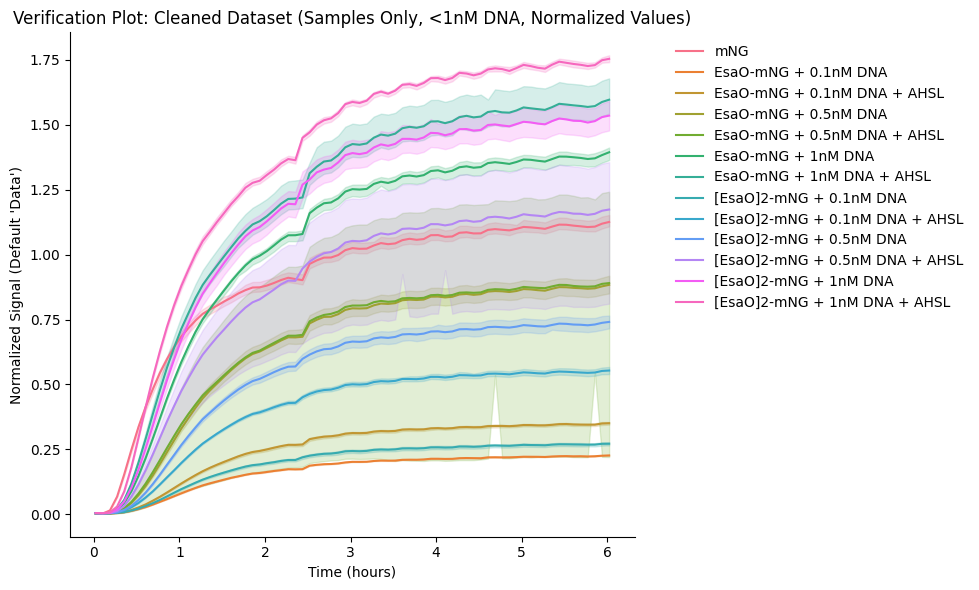

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Load the cleaned CSV
plot_df = pd.read_csv('normalized_samples_only.csv')

# 2. Convert Time column from string back to timedelta, then to hours for easy plotting
plot_df['Time'] = pd.to_timedelta(plot_df['Time'])
plot_df['Time_hrs'] = plot_df['Time'].dt.total_seconds() / 3600.0

# 3. Create the verification plot
plt.figure(figsize=(10, 6))
sns.lineplot(
    data=plot_df,
    x='Time_hrs',
    y='Data',  # This now contains the normalized decimal values!
    hue='Name'
)

plt.title('Verification Plot: Cleaned Dataset (Samples Only, <1nM DNA, Normalized Values)')
plt.xlabel('Time (hours)')
plt.ylabel('Normalized Signal (Default \'Data\')')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', frameon=False)
sns.despine()
plt.tight_layout()
plt.show()

In [ ]:

"""
Side-by-side plate-reader kinetics with a shared y-axis (seaborn).

Edit the CONFIG block below, then run:
    python plot_panels_seaborn.py
"""
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# =============================================================================
# CONFIG — edit these
# =============================================================================

# One dict per panel, left -> right.
#   file    : CSV path
#   title   : panel title
#   include : substring(s) a sample Name must contain to be plotted (None = all)
#   exclude : substring(s) that drop a sample Name (None = nothing dropped)
PANELS = [
    dict(file="normalized_current_run.csv", title="Current run",
         include=["[EsaO]2-mNG"], exclude=None),
    dict(file="normalized_samples_only.csv", title="Samples only",
         include=["[EsaO]2-mNG"], exclude=None),
]

SUPTITLE = "[EsaO]2-mNG DNA template titration ± 5 µM AHSL"
Y_LABEL = "Normalized fluorescence"
X_LABEL = "Time (hrs)"

# What to plot on y:
#   "normalized" -> Data_normalized (fluorescein-calibrated; comparable across days)
#   "raw"        -> raw counts (uses Data_raw if present, otherwise Data)
Y_DATA = "normalized"

# Line grouping. Any column of the CSV works, e.g. "Name", "DNA Template (nM)", "AHSL".
HUE = "Name"          # colour
STYLE = None          # line dash (e.g. "AHSL"); None = all solid
PALETTE = "tab10"     # seaborn palette name, or a list of colours

ERRORBAR = "sd"       # "sd", ("ci", 95), "se", or None for no band
SHARE_Y = True
Y_LIM = None          # e.g. (0, 4500); None = auto
X_LIM = None          # e.g. (0, 6)

FIGSIZE = (11, 4.8)
# Legend placement:
#   "shared" -> one legend under the figure (best when there are many lines)
#   "each"   -> a legend inside every panel at LEGEND_LOC (like the reference plot)
LEGEND_MODE = "shared"
LEGEND_LOC = "lower right"   # used when LEGEND_MODE = "each"
LEGEND_NCOL = 3              # used when LEGEND_MODE = "shared"
LEGEND_FONTSIZE = 9
OUTFILE = "panels_seaborn.png"
DPI = 200

# =============================================================================


def load_panel(cfg):
    df = pd.read_csv(cfg["file"])

    # Filter sample names
    if cfg.get("include"):
        df = df[df["Name"].apply(lambda n: any(s in n for s in cfg["include"]))]
    if cfg.get("exclude"):
        df = df[~df["Name"].apply(lambda n: any(s in n for s in cfg["exclude"]))]

    # y column
    if Y_DATA == "raw":
        df["y"] = df["Data_raw"] if "Data_raw" in df.columns else df["Data"]
    else:
        df["y"] = df["Data_normalized"]

    # Time in hours, aligned across replicate wells (they are read seconds apart)
    df["hours_raw"] = pd.to_timedelta(df["Time"]).dt.total_seconds() / 3600
    df["read_idx"] = df.groupby("Well").cumcount()
    df["hours"] = df.groupby("read_idx")["hours_raw"].transform("mean")

    # Handy grouping column
    df["AHSL"] = df["[AHSL] (uM)"].fillna(0).gt(0).map({True: "+ AHSL", False: "– AHSL"})
    return df


def main():
    sns.set_style("ticks")
    data = [load_panel(p) for p in PANELS]

    # Consistent colours across panels: one colour per hue value, shared by all panels
    hue_order = sorted(pd.concat(d[HUE] for d in data).unique(), key=str) if HUE else None
    colors = dict(zip(hue_order, sns.color_palette(PALETTE, len(hue_order)))) if HUE else None

    fig, axes = plt.subplots(1, len(PANELS), figsize=FIGSIZE, sharey=SHARE_Y, squeeze=False)
    axes = axes[0]

    for ax, cfg, df in zip(axes, PANELS, data):
        sns.lineplot(
            data=df, x="hours", y="y",
            hue=HUE, hue_order=[h for h in hue_order if h in set(df[HUE])] if HUE else None,
            palette=colors, style=STYLE,
            errorbar=ERRORBAR, ax=ax,
        )
        ax.set_title(cfg["title"])
        ax.set_xlabel("")
        ax.set_ylabel("")
        if X_LIM:
            ax.set_xlim(X_LIM)
        if ax.get_legend():
            if LEGEND_MODE == "each":
                sns.move_legend(ax, LEGEND_LOC, frameon=False, fontsize=LEGEND_FONTSIZE, title=None)
            else:
                ax.get_legend().remove()

    if Y_LIM:
        axes[0].set_ylim(Y_LIM)
    axes[0].set_ylabel(Y_LABEL)
    fig.supxlabel(X_LABEL)
    fig.suptitle(SUPTITLE)
    sns.despine(fig)

    if LEGEND_MODE == "shared" and (HUE or STYLE):
        # Collect unique entries across all panels
        seen = {}
        for ax in axes:
            for h, l in zip(*ax.get_legend_handles_labels()):
                seen.setdefault(l, h)
        fig.legend(seen.values(), seen.keys(), loc="lower center", ncol=LEGEND_NCOL,
                   frameon=False, fontsize=LEGEND_FONTSIZE, bbox_to_anchor=(0.5, -0.02))
        fig.tight_layout(rect=(0, 0.04 + 0.045 * -(-len(seen) // LEGEND_NCOL), 1, 1))
        fig.supxlabel(X_LABEL, y=0.03 + 0.045 * -(-len(seen) // LEGEND_NCOL))
    else:
        fig.tight_layout()
    fig.savefig(OUTFILE, dpi=DPI, bbox_inches="tight")
    print(f"Saved {OUTFILE}")


if __name__ == "__main__":
    main()

FileNotFoundError: [Errno 2] No such file or directory: 'normalized_current_run.csv'

If you want to change the time window over which you calculate the average, you can use the `window` argument:

In [ ]:
# data = data.normalize('10 uM HPTS', window=pd.Timedelta("2.5h"))

## Kinetic Analysis

See the [DevNote](https://devnotes.nucleus.engineering/articles/Newman-20260421) on kinetic analysis for more details.

**Metrics extracted:**

  - **Maximum velocity**: Maximum rate of fluorescence increase (slope at inflection point)
  - **Lag time**: Time to reach the exponential phase
  - **Steady-state**: Final fluorescence level
  - **Time-to-completion**: Time it takes to reach 95% of asymptote
  - **Drift**: Rate of signal decay or increase after steady-state
  - **R²**: Goodness of fit; "Good Fit" is `True` if $R^2 \geq 0.95$

In [ ]:
# Perform kinetic analysis using sigmoid_drift model
kinetics = data.fit_kinetics()

[07/16/26 17:29:20] INFO     Calculating Kinetics                analysis.py:223


In [ ]:
kinetics.summary

,Well,Name,Max Velocity,Max Velocity Time,Lag Time,Steady State,Completion Time,Completion Threshold,Drift,Fit Function,R^2,Good Fit,Normalized to
0,B2,tRNA AR-836,2.49,0 days 01:33:15,0 days 00:33:09,4.74,0 days 03:01:44,0.95,0.07,sigmoid_drift,1.00,True,10 uM HPTS
1,B4,tRNA AR-837,2.67,0 days 01:33:35,0 days 00:34:38,4.99,0 days 03:00:24,0.95,0.07,sigmoid_drift,1.00,True,10 uM HPTS
2,B6,tRNA AR-838,2.44,0 days 01:32:35,0 days 00:34:21,4.50,0 days 02:58:17,0.95,0.06,sigmoid_drift,1.00,True,10 uM HPTS
3,B8,tRNA AR-839,1.68,0 days 01:32:00,0 days 00:37:35,2.89,0 days 02:52:07,0.95,0.03,sigmoid_drift,1.00,True,10 uM HPTS
4,B10,tRNA AR-730 (Rxn Control),2.37,0 days 01:30:01,0 days 00:33:50,4.22,0 days 02:52:45,0.95,0.07,sigmoid_drift,1.00,True,10 uM HPTS
5,B12,NEB Positive Control,2.66,0 days 01:35:50,0 days 00:45:09,4.27,0 days 02:50:26,0.95,0.09,sigmoid_drift,1.00,True,10 uM HPTS
6,D2,tRNA AR-836,2.64,0 days 01:31:44,0 days 00:32:12,4.97,0 days 02:59:23,0.95,0.08,sigmoid_drift,1.00,True,10 uM HPTS
7,D4,tRNA AR-837,2.79,0 days 01:32:13,0 days 00:34:27,5.10,0 days 02:57:16,0.95,0.07,sigmoid_drift,1.00,True,10 uM HPTS
8,D6,tRNA AR-838,2.52,0 days 01:32:00,0 days 00:34:31,4.58,0 days 02:56:37,0.95,0.06,sigmoid_drift,1.00,True,10 uM HPTS
9,D8,tRNA AR-839,1.84,0 days 01:30:32,0 days 00:35:41,3.20,0 days 02:51:17,0.95,0.04,sigmoid_drift,1.00,True,10 uM HPTS


## Visualize Fits

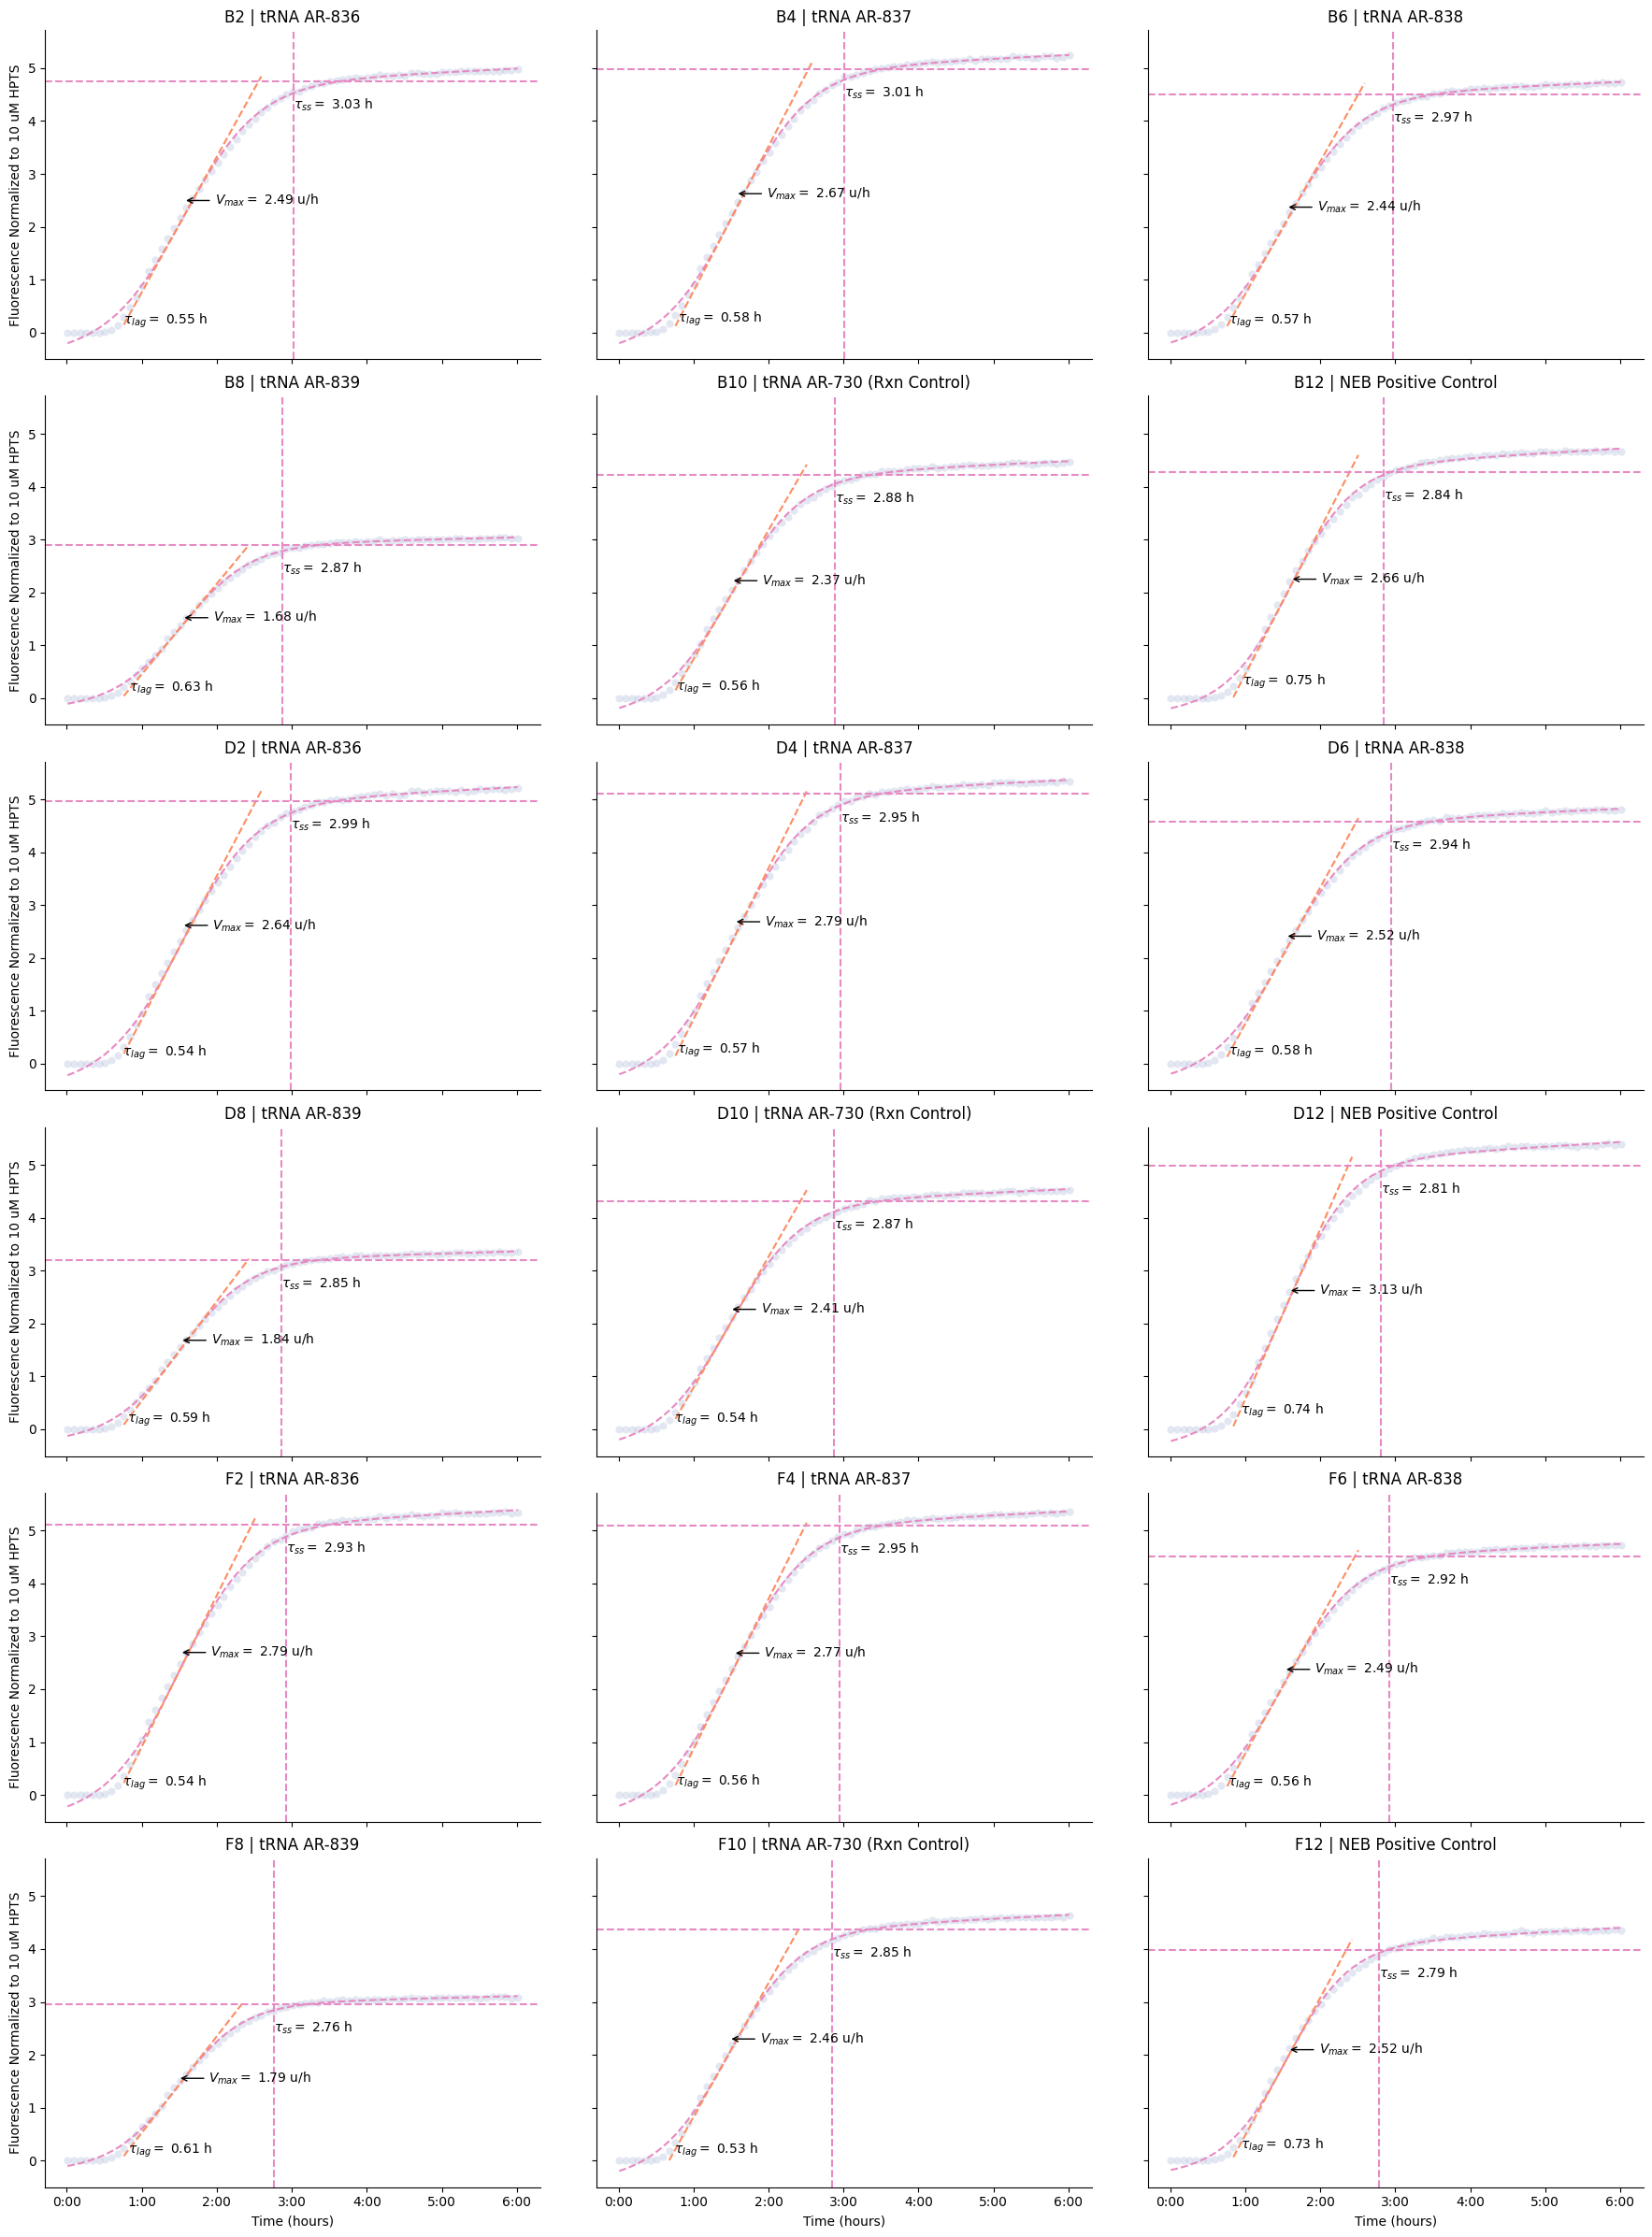

In [ ]:
g = kinetics.plot(col="Well")
# g = kinetics.plot() # call this to visualize across replicates

## Summary Plots

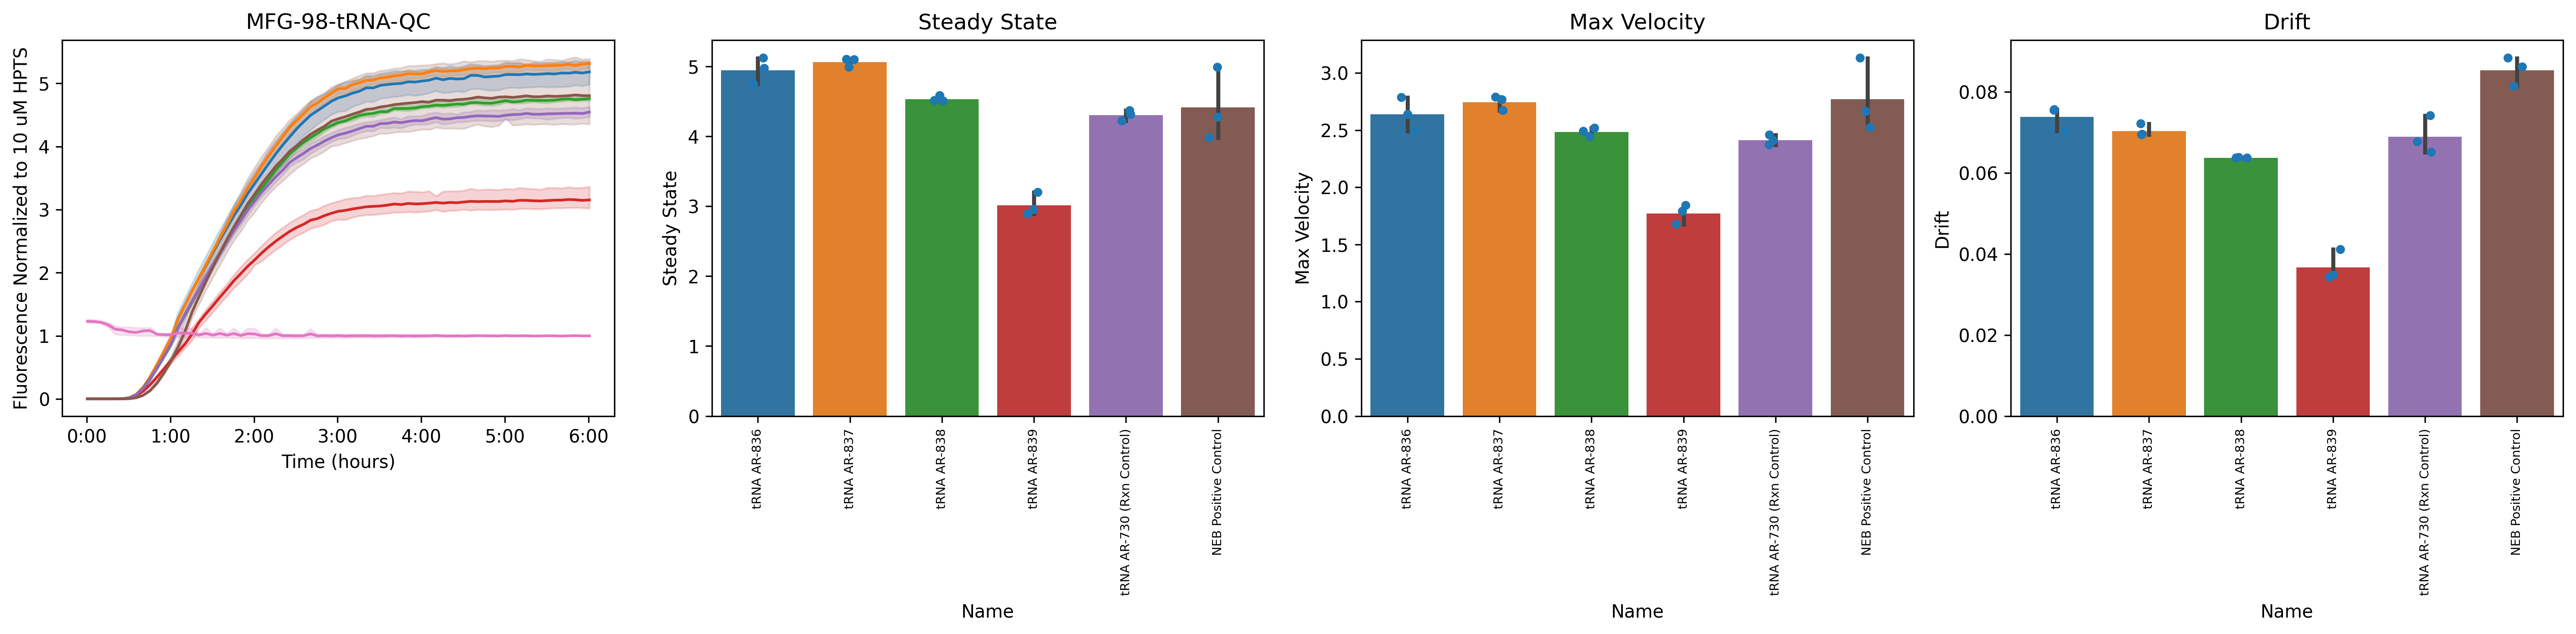

In [ ]:
g = kinetics.plot_summary()

---

## Key Metrics Explained

### 1. **Steady-State Level** (`Steady State, Data`)
- The final fluorescence value reached by the reaction
- Represents the total amount of protein produced
- Higher values indicate greater expression yield

### 2. **Maximum Velocity** (`Velocity, Max`)
- The steepest slope of the fluorescence curve (at the inflection point)
- Units: RFU per second
- Reflects the peak rate of protein synthesis
- Sensitive to enzyme activity, substrate availability, and reaction conditions

### 3. **Lag Time** (`Lag, Time`)
- Time before exponential fluorescence increase begins
- May reflect time for ribosome assembly or initial translation steps
- Shorter lag times suggest faster reaction initiation

### 4. **Drift** (`Fit, drift`)
- Rate of fluorescence change after reaching steady-state
- Positive drift: continued synthesis or aggregation
- Negative drift: photobleaching, protein degradation, or quenching
- Units: RFU per second

### 5. **R² Value** (`Fit, R^2`)
- Goodness of fit (0 to 1, higher is better)
- R² > 0.98 indicates excellent fit
- Poor fits may indicate noisy data, overflow errors, or non-sigmoid kinetics

---

## Tips and Troubleshooting

- **Overflow errors:** Wells with `OVRFLW` or `NaN` values are automatically excluded from fitting
- **Poor fits (low R²):** Inspect raw curves for anomalies (bubbles, evaporation, pipetting errors)
- **Drift:** Sometimes seen in kinetics curves; use `sigmoid_drift` model
- **Multiple replicates:** Always include technical replicates and report error bars
- **Comparing conditions:** Normalize or blank data consistently across all samples

---

## Next Steps

- Export kinetics results: `pr.export_kinetics(kinetics, 'results.csv')`
- Statistical analysis: Use `scipy.stats` or `statsmodels` for ANOVA/t-tests
- Parameter optimization: Vary Mg²⁺, K⁺, or other conditions to maximize Vmax or steady-state
- Mechanistic modeling: Fit ODE models to extract biological rate constants